### Práctica 1: Planificación de misión robótica multi-objetivo

Nuestra primera práctica tiene que ver con algo muy habitual tanto en robótica como en otras disciplinas técnicas: optimización en un entorno con múltiples objetivos que presentan conflictos entre si.

En este caso en particular un robot autónomo debe inspeccionar una instalación industrial. Dispone de una batería limitada y de un tiempo máximo para completar la misión. Hay varios puntos de interés, pero no necesariamente puede visitarlos todos.

Cada punto tiene:
- Posición: coordenadas en el mapa
- Recompensa o prioridad: valor de la información obtenida al inspeccionarlo
- Tiempo de servicio: tiempo que el robot permanece allí realizando la inspección
- Consumo energético de servicio: energía utilizada durante la inspección

El robot parte de una base y debe regresar a ella al finalizar.
Además, cada desplazamiento tiene una distancia, una duración y un coste energético.

Por tanto se debe elegir una solución de compromiso entre recompensa, tiempo y energía, para lo que habrá que tomar ciertas decisiones:
1. Seleccionar los puntos que merece la pena visitar
2. Determinar el orden de visita


#### Entrega de la práctica:
Entrega: Carpeta comprimida con nombre Apellido1_Apellido2_Nombre.zip

Fecha: 16/11/2026 - 23:59

Contacto: david.diazv@uam.es

#### Ejercicio 1. Definición del escenario

Un robot móvil debe realizar tareas de inspección en una planta representada por un mapa 2D. Cada tarea tiene:
- una posición
- una recompensa, que representa su prioridad o valor
- un tiempo de inspección
- un consumo energético asociado a la tarea

El robot parte de una base y dispone de límites de tiempo y energía. En los ejercicios siguientes construiremos y compararemos misiones que seleccionan puntos y deciden en qué orden visitarlos.

En este ejercicio:
1. Definiremos la base y los puntos de inspección
2. Representaremos el mapa y los puntos en una gráfica
3. Calcularemos la distancia euclídea entre dos posiciones

La distancia se medirá en unidades del mapa. Más adelante la usaremos para estimar el tiempo de desplazamiento y el consumo energético.

In [1]:
import numpy as np

In [2]:
# Parámetros del robot
speed = 1.0  # unidades de distancia por unidad de tiempo
consumption = 0.8  # energía consumida por unidad de distancia

In [3]:
# Parámetros de la misión
base = np.array([0.0, 0.0])
max_time = 35.0
max_energy = 45.0
size = 11
tasks = np.array([
    [2.0,  7.0, 12.0, 2.0, 1.5],
    [5.0,  2.0,  8.0, 1.0, 1.0],
    [8.0,  8.0, 15.0, 3.0, 2.0],
    [6.0,  5.0, 10.0, 2.0, 1.2],
    [1.0,  3.0,  6.0, 1.0, 0.8],
    [9.0,  1.0, 11.0, 2.0, 1.4],
    [3.0,  9.0,  9.0, 1.5, 1.0],
    [7.0,  3.0, 13.0, 2.5, 1.8],
])  # Cada fila representa una tarea: [x, y, recompensa, tiempo, energía]

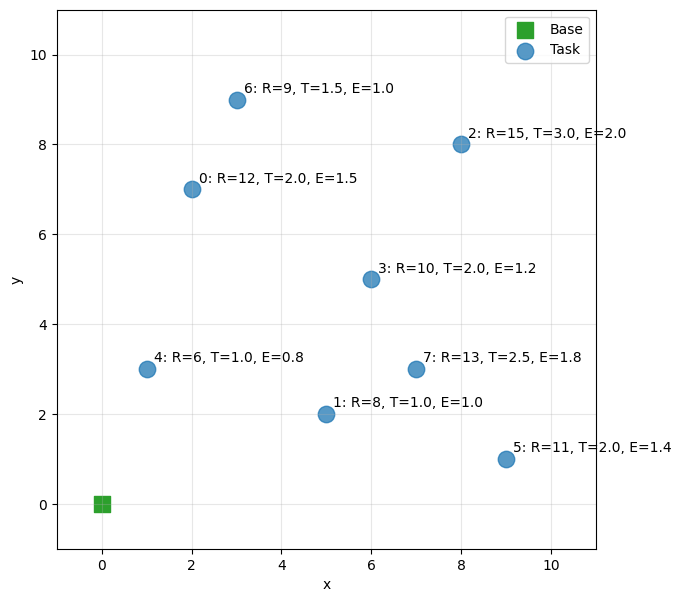

In [4]:
from src.board import plot_board
plot_board(size, base, tasks)

**Tarea:** crea la función `euclidean` para que calcule la distancia euclidea entre dos puntos.

In [5]:
def euclidean(point1, point2):
    return np.linalg.norm(point1 - point2)

In [6]:
print(f"Número de puntos de inspección: {len(tasks)}")
print(f"Tiempo máximo: {max_time}")
print(f"Energía máxima: {max_energy}")
print(f"Distancia entre la base y el punto 0: {euclidean(base, tasks[0, :2]):.2f}")
print(f"Distancia entre la base y el punto 1: {euclidean(base, tasks[1, :2]):.2f}")
print(f"Distancia entre la base y el punto 2: {euclidean(base, tasks[2, :2]):.2f}")
print(f"etc.")

Número de puntos de inspección: 8
Tiempo máximo: 35.0
Energía máxima: 45.0
Distancia entre la base y el punto 0: 7.28
Distancia entre la base y el punto 1: 5.39
Distancia entre la base y el punto 2: 11.31
etc.


#### Ejercicio 2. Evaluación de una misión

Representaremos una misión mediante una lista ordenada de índices. Por ejemplo, `[2, 0, 3]` significa que el robot visita primero el punto 2, después el 0 y finalmente el 3.

El robot debe volver a la base al terminar. Para una misión calcularemos:
- la recompensa total de los puntos visitados
- la distancia total recorrida
- el tiempo total, incluyendo desplazamientos e inspecciones
- la energía total, incluyendo desplazamientos e inspecciones
- si se respetan los límites de tiempo y energía

Usaremos estos modelos sencillos:
- tiempo de desplazamiento = distancia / velocidad
- energía de desplazamiento = distancia × consumo

**Tarea:** completa la función `evaluate_path` para que acumule estas cantidades a lo largo de la ruta y las devuelva junto con un flag que indique si esta es factible.

In [7]:
from src.paths import evaluate_path

In [8]:
path = [2, 0, 3]
result = evaluate_path(base, tasks, path, euclidean, speed=speed, consumption=consumption, max_time=max_time, max_energy=max_energy)
print("Ruta:", path)
print(f"Recompensa: {result['reward']:.2f}")
print(f"Distancia:  {result['distance']:.2f}")
print(f"Tiempo:     {result['time']:.2f} / {max_time:.2f}")
print(f"Energía:    {result['energy']:.2f} / {max_energy:.2f}")
print("¿Misión factible?:", result["feasible"])

Ruta: [2, 0, 3]
Recompensa: 37.00
Distancia:  29.68
Tiempo:     36.68 / 35.00
Energía:    28.44 / 45.00
¿Misión factible?: False


#### Ejercicio 3. Planificador voraz: vecino más cercano

Implementaremos una estrategia voraz (greedy) sencilla:
1. El robot empieza en la base
2. Busca el punto no visitado más cercano
3. Añade ese punto a la ruta solo si la misión resultante sigue siendo factible, incluido el regreso a la base
4. Repite hasta que no pueda añadir ningún otro punto

Esta estrategia es rápida y fácil de entender, pero no garantiza la misión con mayor recompensa.

**Tarea:** completa la función `nearest_neighbor` que devuelva la secuencia de índices de los puntos a visitar.

In [9]:
from src.paths import nearest_neighbor

In [10]:
path = nearest_neighbor(base, tasks, euclidean, speed=speed, consumption=consumption, max_time=max_time, max_energy=max_energy)
result = evaluate_path(base, tasks, path, euclidean)
print("Ruta obtenida:", path)
print(f"Recompensa: {result['reward']:.2f}")
print(f"Distancia:  {result['distance']:.2f}")
print(f"Tiempo:     {result['time']:.2f} / {max_time:.2f}")
print(f"Energía:    {result['energy']:.2f} / {max_energy:.2f}")
print("¿Misión factible?:", result["feasible"])

Ruta obtenida: [4, 0, 6, 3, 7, 1]
Recompensa: 58.00
Distancia:  24.38
Tiempo:     34.38 / 35.00
Energía:    31.68 / 45.00
¿Misión factible?: True


#### Ejercicio 4. Análisis multiobjetivo y frontera de Pareto

Estamos teniendo en cuenta tres objetivos:
- maximizar la recompensa
- minimizar el tiempo
- minimizar la energía

Una misión puede ofrecer más recompensa y, a la vez, consumir más tiempo o energía. Por eso no siempre existe una única solución que sea mejor en todos los criterios.

Se dice que una solución domina a otra si obtiene al menos tanta recompensa, tarda como máximo lo mismo y consume como máximo la misma energía, siendo estrictamente mejor en al menos uno de esos criterios. Las soluciones factibles que no están dominadas forman la **frontera de Pareto**.

Como el escenario solo tiene ocho puntos, podemos enumerar todas las rutas posibles. Para escenarios grandes, esta estrategia deja de ser práctica y se necesitarían métodos de optimización más avanzados.

In [11]:
from src.pareto import pareto_front
from src.paths import feasible_paths

In [12]:
paths = feasible_paths(base, tasks, euclidean, speed=speed, consumption=consumption, max_time=max_time, max_energy=max_energy)
print("Número de misiones factibles:", len(paths))
front = pareto_front(paths)
print("Número de soluciones Pareto:", len(front))

Número de misiones factibles: 753
Número de soluciones Pareto: 27


#### Ejercicio 5. Mapa en cuadrícula y obstáculos

Representaremos ahora la planta como una cuadrícula en la que podrá haber obstáculos. Cada celda será:
- libre, si el robot puede atravesarla
- ocupada, si contiene un obstáculo

El robot y las tareas se ubicarán en las celdas libres más cercanas a sus coordenadas del escenario continuo. En el siguiente ejercicio implementaremos A* para encontrar rutas que eviten los obstáculos.

In [13]:
# En la cuadrícula, 0 representa una celda libre y 1 un obstáculo
walls = np.zeros((size, size), dtype=int)
# Añadimos paredes con huecos para que existan varios pasos posibles
walls[1:8, 6] = 1
walls[5, 6] = 0
walls[3:10, 4] = 1
walls[8, 4] = 0
walls[7, 4:9] = 1
walls[7, 7] = 0

**Tarea:** completa la función `validate_board` que compruebe (pista: usa `assert`) si el tablero es válido, es decir, que la base y las tareas están en casillas libres y dentro del tablero.

In [14]:
from src.board import validate_board

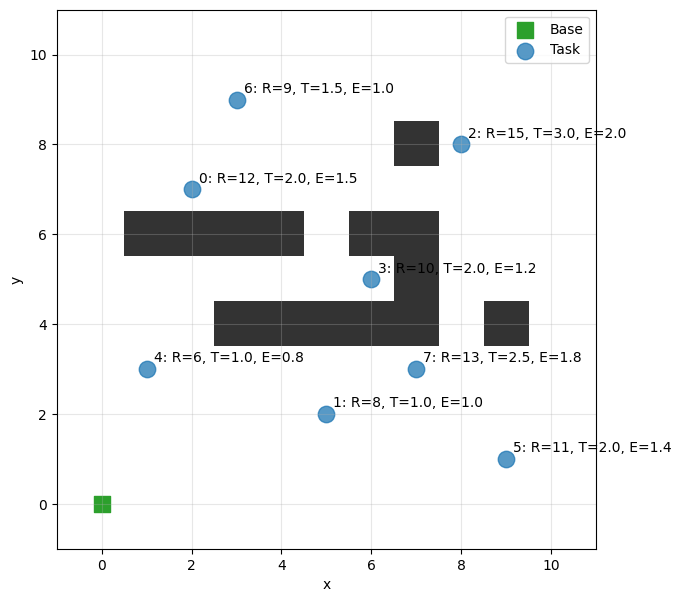

In [15]:
validate_board(base, tasks, walls=walls, size=size)
plot_board(size, base, tasks, walls=walls)

#### Ejercicio 6. Búsqueda de caminos con A*

Implementaremos A* para encontrar un camino entre dos celdas libres del mapa. El algoritmo combina:
- el coste acumulado desde el inicio, `g(n)`
- una estimación del coste restante hasta el objetivo, `h(n)`

La prioridad de exploración es `f(n) = g(n) + h(n)`. Para movimientos en cuatro direcciones y coste uniforme, usaremos la distancia Manhattan como heurística:

\[
h(n) = |fila_n - fila_{objetivo}| + |columna_n - columna_{objetivo}|
\]

**Tarea:** crea la función `manhattan` que calcule la distancia de Manhattan entre dos puntos.

In [ ]:
# EDITA ESTA CELDA
manhattan = lambda ...

**Tarea:** completa la función `astar` que devuelva una lista de listas/tuplas con las coordenadas de los puntos que se deben ir visitando para viajar entre dos localizaciones.

In [ ]:
from src.paths import astar

In [ ]:
objective = tasks[2][:2]
path = astar(base, objective, walls, size, dist=manhattan)
print("Inicio:", base)
print("Objetivo:", objective)
print("Número de pasos:", len(path) - 1 if path else None)
print("Camino:", path)
plot_board(size, base, tasks, walls=walls, path=[path])

#### Ejercicio 7. Resolución de misiones con planificación voraz y caminos calculados por A*

El evaluador anterior suponía que el robot podía desplazarse en línea recta. Ahora se usará la longitud de los caminos encontrados por A* en el mapa con obstáculos.

Cada movimiento entre celdas cuesta una unidad de distancia. Por tanto:
- distancia del tramo = número de movimientos del camino
- tiempo de desplazamiento = distancia / velocidad
- energía de desplazamiento = distancia × energía por unidad

El tiempo y la energía de inspección se siguen sumando en cada punto visitado. La misión empieza y termina en la base.

In [ ]:
def astar_dist(a, b, walls=walls, size=size, dist=manhattan):
    path =  astar(a, b, walls, size, dist=dist)
    return len(path) - 1

In [ ]:
path = [2, 0, 3]
result = evaluate_path(base, tasks, path, dist=astar_dist, speed=speed, consumption=consumption, max_time=max_time, max_energy=max_energy)
print("Ruta:", path)
print(f"Recompensa: {result['reward']:.2f}")
print(f"Distancia en cuadrícula: {result['distance']:.2f}")
print(f"Tiempo: {result['time']:.2f} / {max_time:.2f}")
print(f"Energía: {result['energy']:.2f} / {max_energy:.2f}")
print("¿Misión factible?:", result["feasible"])

**Tarea:** completa la función `mission_solver` que haga lo siguiente:
1. Planificar una secuencia de puntos a visitar (empezando y terminando en la base)
2. Para cada uno de esos pasos a dar, calcular el camino a seguir
3. Devolver el camino completo como lista de listas

In [ ]:
from src.paths import mission_solver

In [ ]:
path = mission_solver(base, tasks, walls, size, dist=manhattan, planner=nearest_neighbor, pathfinder=astar, speed=speed, consumption=consumption, max_time=max_time, max_energy=max_energy)
plot_board(size, base, tasks, walls=walls, path=path)